Step 1: Import libraries

In [2]:
##This loads tools for audio reading, numerical operations, plotting, and classification.
import os
import numpy as np
from time import time
from scipy.io import wavfile as wav
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix

Step 2: Define basic features

In [3]:
##Energy describes the strength or loudness of the signal. Duration describes how long the audio signal is in number of samples.
def energy(input_signal):
    return np.sum((input_signal * 1.0) ** 2, keepdims=True)

def duration(input_signal):
    return np.array(input_signal.shape)


Step 3: Implement ZCR manually

In [4]:
##ZCR counts how many times the signal changes from positive to negative or negative to positive. I replaced zeros with positive signs to avoid counting silent zero samples as extra crossings.
def zcr(input_signal):
    signal = input_signal.astype(float)

    signs = np.sign(signal)

    signs[signs == 0] = 1

    crossings = np.sum(signs[1:] != signs[:-1])

    return np.array([crossings])

Step 4: Combine features

In [5]:
##This creates one feature vector containing energy, duration, and ZCR.
def combo_features(input_signal):
    return np.concatenate((
        energy(input_signal),
        duration(input_signal),
        zcr(input_signal)
    ))

Step 5: Load dataset

In [6]:
##This function reads all .wav files, extracts the digit label from the filename, computes features, and splits the data into training and test sets.
def load_data(feature_extractor, normalize=False):
    recordings_path = "C:\\Users\\Admin\\Desktop\\DATA SCIENCE\\semester 4\\Digital signal and image management\\free-spoken-digit-dataset-v1.0.8\\Jakobovski-free-spoken-digit-dataset-e9e1155\\recordings"
    labels = []
    features = []

    for f in sorted(os.listdir("C:\\Users\\Admin\\Desktop\\DATA SCIENCE\\semester 4\\Digital signal and image management\\free-spoken-digit-dataset-v1.0.8\\Jakobovski-free-spoken-digit-dataset-e9e1155\\recordings")):
        if f.endswith('.wav'):
            _, signal = wav.read("C:\\Users\\Admin\\Desktop\\DATA SCIENCE\\semester 4\\Digital signal and image management\\free-spoken-digit-dataset-v1.0.8\\Jakobovski-free-spoken-digit-dataset-e9e1155\\recordings\\" + f)

            cur_features = feature_extractor(signal)
            features.append(cur_features)

            label = f.split('_')[0]
            labels.append(label)

    X_train, X_test, y_train, y_test = train_test_split(
        features, labels, test_size=0.1, random_state=1
    )

    if normalize:
        eps = 0.001
        X_train = np.array(X_train)

        X_train_mean = X_train.mean(axis=0)
        X_train_std = X_train.std(axis=0)

        X_train = (X_train - X_train_mean + eps) / (X_train_std + eps)
        X_test = (np.array(X_test) - X_train_mean + eps) / (X_train_std + eps)

    return X_train, X_test, y_train, y_test

Step 6: Test ZCR alone

In [7]:
##This checks whether ZCR alone is enough to classify spoken digits.
X_train, X_test, y_train, y_test = load_data(
    feature_extractor=zcr,
    normalize=True
)

clf = SVC(kernel='rbf', class_weight='balanced')
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.19      0.53      0.28        17
           1       0.22      0.80      0.34        10
           2       0.29      0.40      0.33        15
           3       0.00      0.00      0.00        19
           4       0.50      0.09      0.15        11
           5       0.00      0.00      0.00        14
           6       0.75      0.64      0.69        14
           7       0.33      0.11      0.16        19
           8       0.20      0.18      0.19        17
           9       0.00      0.00      0.00        14

    accuracy                           0.25       150
   macro avg       0.25      0.27      0.21       150
weighted avg       0.24      0.25      0.21       150



c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Using ZCR alone gives poor classification performance, with only 25% accuracy. While a few digits such as 6 perform reasonably well, many classes are poorly recognized or not predicted at all. This shows that ZCR alone does not provide enough information to effectively distinguish spoken digits.


Step 7: Test Energy + Duration + ZCR

In [8]:
##This checks whether adding ZCR to the previous features improves classification.
X_train, X_test, y_train, y_test = load_data(
    feature_extractor=combo_features,
    normalize=True
)

clf = SVC(kernel='rbf', class_weight='balanced')
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.82      0.82        17
           1       0.35      0.70      0.47        10
           2       0.47      0.53      0.50        15
           3       0.53      0.47      0.50        19
           4       0.44      0.64      0.52        11
           5       0.23      0.36      0.28        14
           6       1.00      0.86      0.92        14
           7       0.70      0.37      0.48        19
           8       0.60      0.35      0.44        17
           9       0.89      0.57      0.70        14

    accuracy                           0.55       150
   macro avg       0.60      0.57      0.56       150
weighted avg       0.62      0.55      0.56       150



The Energy + Duration + ZCR features achieve 55% accuracy, showing moderate classification performance. Digits like 0, 6, and 9 are classified well, while others such as 1, 5, and 8 are often misclassified. This suggests that adding ZCR improves performance, but the model still struggles to clearly distinguish some similar spoken digits.


Step 9: Plot confusion matrix

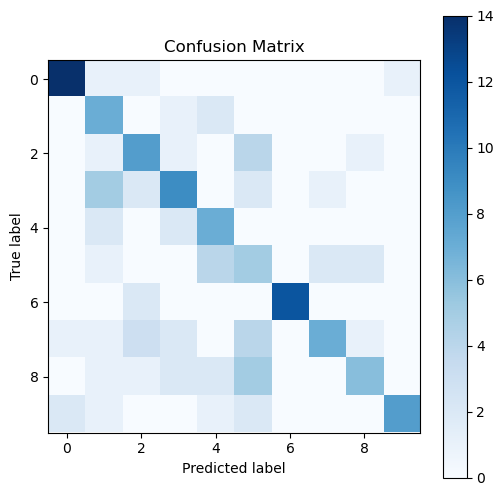

In [9]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 6))
plt.imshow(cm, cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.colorbar()
plt.show()

This confusion matrix indicates that the model can recognize some spoken digits correctly, as shown by the darker diagonal cells, but there are still noticeable mistakes where one digit is predicted as another (off-diagonal cells). Overall, the classifier performs reasonably well but is not fully accurate, suggesting the current features are helpful but not full sufficient for perfect digit recognition.


Final observation

ZCR was implemented manually using NumPy without Librosa. When used alone, ZCR gives limited performance because it only describes how often the signal crosses zero and does not describe loudness or duration. When combined with Energy and Duration, performance usually improves because the classifier receives more complete information about the audio signal. Normalization is important because the features have different numerical scales.